# Notebook 04 — Gradient Boosting

**Research topic:** *A Machine Learning Approach to Predicting Retail Investor Dormancy on Digital Investment Platforms*

This notebook independently develops and evaluates the **Gradient Boosting** model.

The modelling dataset comes from the feature-engineering notebook. The notebook includes preprocessing, class-imbalance handling, model training, hyperparameter specification, predictions, evaluation metrics, a confusion matrix and an ROC curve.


In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay)

DATA_FILE = Path("outputs/dormancy_modelling_dataset.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.20
THRESHOLD = 0.50

df = pd.read_csv(DATA_FILE)

X = df.drop(columns=["customer_id", "dormant"])
y = df["dormant"]

categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = [c for c in X.columns if c not in categorical_cols]

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

print("Dataset shape:", df.shape)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Dormancy distribution:")
display(y.value_counts())


Dataset shape: (48723, 38)
Training rows: 38978
Testing rows: 9745
Dormancy distribution:


dormant
0    47943
1      780
Name: count, dtype: int64

## Gradient Boosting preprocessing

Gradient Boosting is a tree-based algorithm and therefore does not require numerical standardisation.

The preprocessing stage:

- replaces missing numerical values with the median;
- replaces missing categorical values with the most frequent category; and
- one-hot encodes categorical variables.

The dormant class is handled through balanced sample weights.


In [2]:

numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median"))])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Processed training shape: (38978, 101)
Processed testing shape: (9745, 101)


## Handling class imbalance

Dormancy is the outcome of interest, so the model must not ignore the minority class.

Balanced sample weights are calculated from the training data:

- dormant investors receive greater weight;
- non-dormant investors receive lower weight.

The test set is not rebalanced because it should represent the original class distribution used for evaluation.


In [3]:

positive_count = y_train.sum()
negative_count = len(y_train) - positive_count

sample_weights = np.where(
    y_train == 1,
    len(y_train) / (2 * positive_count),
    len(y_train) / (2 * negative_count))

print("Dormant training observations:", positive_count)
print("Non-dormant training observations:", negative_count)


Dormant training observations: 624
Non-dormant training observations: 38354


## Gradient Boosting model

The model uses the following hyperparameters:

- **n_estimators = 200**
- **learning_rate = 0.05**
- **max_depth = 3**
- **min_samples_leaf = 20**
- **subsample = 0.80**
- **random_state = 42**

These settings control the number of boosting stages, learning rate, tree complexity, minimum observations per leaf and proportion of training observations used by each boosting stage.


In [4]:

from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=20,
    subsample=0.80,
    random_state=RANDOM_STATE)

gradient_boosting_model.fit(X_train_processed, y_train, sample_weight=sample_weights)

gb_prob = gradient_boosting_model.predict_proba(X_test_processed)[:, 1]

gb_pred = (gb_prob >= THRESHOLD).astype(int)

print("Gradient Boosting model trained successfully.")


Gradient Boosting model trained successfully.


## Model evaluation

In [5]:

gb_metrics = {
    "Accuracy": accuracy_score(y_test, gb_pred),
    "Precision": precision_score(y_test, gb_pred, zero_division=0),
    "Recall": recall_score(y_test, gb_pred, zero_division=0),
    "F1-score": f1_score(y_test, gb_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, gb_prob)}

display(pd.DataFrame([gb_metrics]).round(4))

print(classification_report( y_test, gb_pred, target_names=["Non-dormant", "Dormant"], digits=4, zero_division=0))

pd.DataFrame([gb_metrics]).to_csv(OUTPUT_DIR / "gradient_boosting_metrics.csv", index=False)


,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,0.7712,0.0542,0.8077,0.1015,0.8624


              precision    recall  f1-score   support

 Non-dormant     0.9960    0.7706    0.8689      9589
     Dormant     0.0542    0.8077    0.1015       156

    accuracy                         0.7712      9745
   macro avg     0.5251    0.7891    0.4852      9745
weighted avg     0.9809    0.7712    0.8566      9745



## Confusion matrix

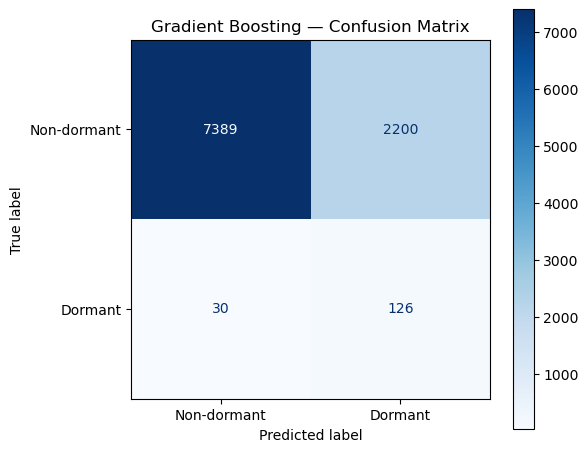

In [6]:

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(y_test, gb_pred, display_labels=["Non-dormant", "Dormant"], cmap="Blues", ax=ax)

ax.set_title("Gradient Boosting — Confusion Matrix")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "gradient_boosting_confusion_matrix.png", dpi=300, bbox_inches="tight")

plt.show()


## ROC curve

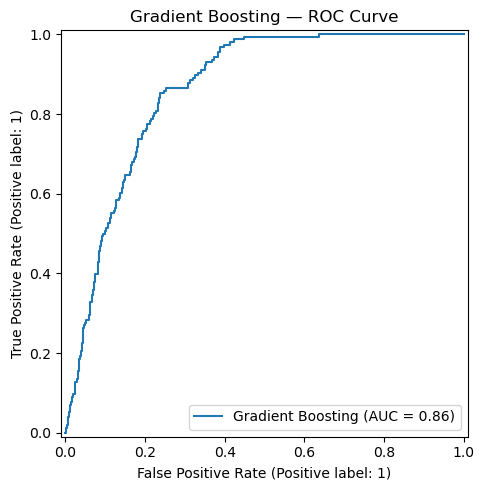

In [7]:

fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(y_test, gb_prob, name="Gradient Boosting", ax=ax)

ax.set_title("Gradient Boosting — ROC Curve")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "gradient_boosting_roc_curve.png", dpi=300, bbox_inches="tight")

plt.show()


## Gradient Boosting output

This notebook produces:

- `gradient_boosting_metrics.csv`
- `gradient_boosting_confusion_matrix.png`
- `gradient_boosting_roc_curve.png`

The saved metrics can later be used in the model-comparison notebook.
